# Case Study 25 — "2× Productivity": Evaluating an AI Claims Copilot for Extraction Accuracy, Speed, Decision Quality and Automation Bias

**Priority:** ★ Optional · **Reference:** Case Study 25 — *ICICI Lombard: health-claims adjudication copilot (OCR + LLM)* (`indian_fintech_data_science_case_studies.md`)
**Audience:** Head of Health Claims, Claims Audit, Medical Panel, Operations
**Data:** ⚠️ **SYNTHETIC** (D-25-01). Claim documents are confidential. We simulate the *records of an evaluation*, not documents or LLM text.
**Reproducibility:** seed = 42 · `python -m nbconvert --to notebook --execute --inplace cs25_claims_copilot_evaluation.ipynb`

## 0. Executive Summary for Business

*(Synthetic evaluation records for a copilot like ICICI Lombard's; the vendors disclosed only "2×" and ">50%". Written after the analysis.)*

- **The question:** does the AI claims copilot deliver the reported "2× productivity" without making claim decisions worse?
- **Speed: yes, close to the claim.** In a randomised test of 6,000 claims, AI-assisted adjudication took a median **41.8 minutes vs 75.1** (time ratio **0.56**, CI 0.55–0.57; **44% less time**, **1.8× more claims per adjudicator-day**). The saving is the same on simple and complex claims. This is slightly short of the documented "over 50%" and "2×", but the same order.
- **Quality: no sign of harm, but the proof is thin.** Decision accuracy vs the true outcome was **84.7% (AI) vs 84.5% (manual)**, non-inferior within 2 pp (CI −1.7 to +2.0). Disputes are unchanged (7.1% vs 7.4%). However, on the realistic **10% gold-audited sample** (546 claims) the interval is ±6 pp, so *non-inferiority cannot be shown* with an audit that small. Proving a 2 pp margin needs ≈ 4,000 audited claims per arm.
- **The main risk is automation bias:** the summary is wrong in **8.7%** of AI-assisted claims (46% of them complex), and when it is wrong adjudicators are right only **74%** of the time vs **86%** when it is right (−11.7 pp, p ≈ 3e-6). That costs ≈ 30 extra wrong decisions in this study, offset by gains elsewhere.
- **Extraction accuracy is good but not enough to skip checking:**
  - Fields are extracted correctly **92%** of the time; only **57% of claims** have all 8 fields right.
  - Handwritten documents have **2.7×** and scans **7.7×** the error odds of clean print.
  - The risk-flag ("pre-existing") field and procedure code are weakest (84% and 89%).
- **The model knows when it is unsure** (confidence AUC 0.92): flagging the 21% least-confident fields for "verify" catches **84% of errors** and leaves 1.6% of unflagged fields wrong.
- **The guideline check** finds 74% of treatment deviations (specificity 93%); **28% of its flags are false alarms**.
- **₹ impact (2 lakh claims/month):** ≈ **125,000 adjudicator-hours a month** freed (≈ 840 FTE) and a net saving of ≈ **₹10.6 crore/month** after copilot costs. Decision-error cost is unchanged.
- **I recommend:**
  - Roll out with human decision-making, with a "verify" flag on low-confidence fields.
  - Force source-page links for every summary fact.
  - Add a 2-click "I checked the source" step for the guideline flag and for handwritten files.
  - Audit ≥ 1,000 gold-labelled claims a quarter to keep the quality claim honest.

## 1. The Problem in Simple English

A health-insurance adjudicator reads **20+ pages per claim** (discharge summary, lab reports, bills, handwritten notes) and decides to approve, part-pay or reject. ICICI Lombard added a **copilot**: OCR reads the documents, a language model structures the key facts (diagnosis, dates, bill, procedure), checks the treatment against national guidelines and writes a summary. Humans still decide. The reported benefit is "**2× productivity**" and a more than 50% cut in processing time.

For a regulated, money-moving decision, leaders need more than a time saving:
1. **Is the extraction accurate** on messy, handwritten documents, and does the copilot know when it is unsure?
2. **Is the time saving real**, measured in a fair experiment?
3. **Are decisions still correct?** A confident but wrong summary can **anchor** a busy adjudicator (automation bias).
4. **Does the guideline check work**, in terms of both missed deviations and false alarms?

## 2. Reference from the Case File

### (a) What ICICI Lombard did — *documented*

| Item | Documented fact (quoted from the reference file) |
|---|---|
| Problem | "Adjudicators read 20+ pages per claim … One adjudication took several hours" |
| Question | "Can documents be structured automatically and checked against policy terms and treatment guidelines, so adjudicators decide faster and more consistently?" |
| Approach | OCR/document extraction → structuring into diagnosis, presentation, history, treatment, labs → comparison with NHA and disease guidelines → summary for the adjudicator |
| ML | Azure OCR / Document Intelligence + Azure OpenAI + an "indigenous model" (Microsoft); Gemini (Google); target / validation / metrics **ND** |
| Decision | Adjudicators work from AI summaries and guideline checks; "humans remain the decision-makers" |
| Impact | "**2x** productivity increase"; processing time cut "by over **50%**" (Microsoft); adjudication "to just a few minutes" (Google) |

### (b) What *we* simulate and add

| Item | Our choice |
|---|---|
| Part A (extraction audit) | 4,000 claims × 8 key fields, with true vs extracted values, document quality (clean print / scan / handwritten), pages and model confidence |
| Part B (productivity) | A **randomised** study of 6,000 claims by 60 adjudicators; half got the copilot summary. Outcomes: handling minutes, decision, a 10% **gold-audited** subsample (3 senior adjudicators), later disputes. 6–14% of AI summaries contain an error (automation-bias risk). |
| Part C (guidelines) | 1,500 claims: copilot "deviation" flags vs an expert's judgement |
| Statistics added | Per-field accuracy with Wilson CIs; logistic model of extraction errors on quality/pages; confidence calibration and **selective review**; **cluster-aware** randomised comparison of time (mixed model, log scale, ratio with CI, Mann–Whitney); decision accuracy vs gold (two-proportion, equivalence-style **non-inferiority**); effect of a wrong summary (automation bias); sensitivity/specificity of the guideline check; sample sizes |

### (c) How the industry uses this

LLM "copilots" for claims, KYC and underwriting are being piloted across Indian insurers and banks (ICICI Lombard, Star Health, Bajaj Allianz, HDFC ERGO, Niva Bupa) with vendors on Azure OpenAI, Google Gemini and local OCR providers. IRDAI expects human accountability for claim decisions and a clear audit trail, which makes **"decision support with measured quality"** the standard pattern. The evaluation here (extraction audit, randomised productivity test, gold-panel quality, automation-bias check) is what a model-risk or claims-audit committee asks for.

## 3. Business Question → Analytical Question → Statistical Hypotheses

| Level | Statement |
|---|---|
| Business | Does the copilot make adjudication faster without making decisions worse, and where is human review essential? |
| Analytical | What are the copilot's extraction error rates and where, how much handling time does it save in a randomised test, and are decision quality and disputes unaffected (non-inferior)? |

**Hypotheses**
- **H1 (extraction):** H0: error rate does not depend on document quality (logistic LR test).
- **H2 (time):** H0: AI-assisted handling time = manual (log-scale mixed model, adjudicator random effect; randomised arms).
- **H3 (quality):** H0: AI-assisted decision accuracy is *inferior* to manual by more than **2 pp** (non-inferiority on the gold-audited subsample).
- **H4 (automation bias):** H0: when the AI summary is wrong, adjudicators are no more likely to be wrong than when it is right.

**Primary metric:** median handling time ratio (AI/manual) **and** decision accuracy vs gold (non-inferior). **Guardrails:** dispute rate; accuracy on complex claims.

In [1]:
import sys, warnings, importlib, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportion_confint, confint_proportions_2indep, proportions_ztest
from statsmodels.stats.multitest import multipletests
from sklearn.metrics import roc_auc_score

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(np.random.SeedSequence(SEED).spawn(1)[0])
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
print("ready")

ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Public health-claim documents with adjudication outcomes | **None.** Claims data are confidential medical and financial records (DPDP Act). Public medical-text sets (MIMIC, i2b2) are US-based and restricted. |
| **Decision** | Simulated evaluation records for the three study parts (D-25-01) |

### 4.2 Generator — clearly marked section

In [2]:
%%writefile data/generate_cs25.py
"""
SYNTHETIC DATA GENERATOR - CASE STUDY 25 (ICICI Lombard-style health-claims copilot: OCR + LLM decision support)
==============================================================================================================
THIS DATA IS SYNTHETIC. Health claim documents and adjudication data are confidential. We do not simulate
documents or LLM text; we simulate what an EVALUATION of such a copilot records.

Part A - extraction audit: 4,000 claims x 8 key fields (diagnosis code, admission date, discharge date, total bill,
room rent, ICU days, pre-existing flag, procedure code), each with the true value, the OCR+LLM extracted value,
and document quality (clean print / scan / handwritten). Handwriting and low-quality scans cause more errors.
Part B - adjudication productivity study: 6,000 claims adjudicated by 60 adjudicators; a RANDOMISED 50% got the
copilot summary (AI-assisted), 50% the manual process. Outcomes: handling minutes, the decision (approve/partial/
reject), the gold decision (panel of 3 senior adjudicators on a 600-claim audit subsample), and whether the claim
was later disputed. Complex claims (many pages, ICU, high value) take longer; the copilot saves more time on
long files but can anchor adjudicators on a wrong summary (automation bias).
Part C - guideline check: for 1,500 claims, whether the copilot flagged a treatment as deviating from NHA/disease
guidelines vs an expert's judgement.

Calibration anchors (reference file, Case Study 25): adjudicators read 20+ pages per claim, "several hours";
"2x productivity increase"; processing time cut "by over 50%"; adjudication "to just a few minutes"; humans
remain the decision-makers; no accuracy metrics disclosed. Rates are our assumptions (decision.md D-25-02).
Hidden truth columns start with "_".

Outputs: data/cs25/extraction_audit.csv.gz, data/cs25/adjudication.csv.gz, data/cs25/guideline_check.csv.gz
"""
import os
import numpy as np
import pandas as pd
from scipy.special import expit

SEED = 42
FIELDS = ["diagnosis_code", "admission_date", "discharge_date", "total_bill", "room_rent", "icu_days", "pre_existing_flag", "procedure_code"]
BASE_ERR = {"diagnosis_code": 0.07, "admission_date": 0.03, "discharge_date": 0.03, "total_bill": 0.04, "room_rent": 0.06, "icu_days": 0.05, "pre_existing_flag": 0.12, "procedure_code": 0.09}
QUAL_MULT = {"clean_print": 0.5, "scan": 1.4, "handwritten": 3.2}


def generate(seed=SEED):
    rng = np.random.default_rng(seed)
    # ---- Part A: extraction audit ----
    n = 4000; q = rng.choice(list(QUAL_MULT), n, p=[0.45, 0.38, 0.17]); pages = np.clip(rng.gamma(4, 5, n), 3, 90).round()
    rows = []
    for f in FIELDS:
        p_err = np.clip(BASE_ERR[f] * pd.Series(q).map(QUAL_MULT).values * (1 + 0.012 * (pages - 20)), 0.002, 0.7)
        err = rng.random(n) < p_err; conf = np.where(err, np.clip(rng.beta(3, 3, n), 0.2, 0.95), np.clip(rng.beta(7, 1.5, n), 0.3, 1.0))
        rows.append(pd.DataFrame({"claim_id": [f"CL{i:05d}" for i in range(n)], "field": f, "doc_quality": q, "pages": pages, "extraction_correct": (~err).astype(int), "model_confidence": conf.round(3)}))
    ext = pd.concat(rows, ignore_index=True)
    # ---- Part B: randomised productivity study ----
    m = 6000; adj = rng.integers(0, 60, m); speed = np.exp(rng.normal(0, 0.25, 60)); skill = rng.normal(0, 0.5, 60)
    pg = np.clip(rng.gamma(4, 5, m), 3, 90).round(); icu = (rng.random(m) < 0.14).astype(int); value = np.exp(rng.normal(np.log(110000), 0.8, m))
    complex_ = ((pg > 40) | (icu == 1) | (value > 300000)).astype(int)
    ai = (rng.random(m) < 0.5).astype(int)
    base_min = np.exp(rng.normal(np.log(75), 0.35, m)) * (0.6 + 0.02 * pg) * speed[adj] * np.where(icu == 1, 1.3, 1)
    save = np.where(ai == 1, np.clip(0.35 + 0.004 * pg + rng.normal(0, 0.08, m), 0.1, 0.8), 0.0)
    minutes = np.round(base_min * (1 - save), 1)
    # true correct decision; adjudicators have skill noise; AI summary has 9% wrong cases that can anchor
    truth = rng.choice(["approve", "partial", "reject"], m, p=[0.62, 0.26, 0.12])
    sum_wrong = (rng.random(m) < np.where(complex_ == 1, 0.14, 0.06)); sum_wrong = sum_wrong & (ai == 1)
    p_ok = expit(1.9 + 0.5 * skill[adj] - 0.6 * complex_ - 0.35 * (ai == 0) * (pg > 40) - 1.1 * sum_wrong * (rng.random(m) < 0.55) + 0.1 * (ai == 1))
    correct = rng.random(m) < p_ok
    wrong_choices = np.array([[c for c in ["approve", "partial", "reject"] if c != t][rng.integers(2)] for t in truth])
    decision = np.where(correct, truth, wrong_choices)
    disputed = ((~correct) & (rng.random(m) < 0.30)) | ((correct) & (rng.random(m) < 0.03))
    df = pd.DataFrame({"claim_id": [f"AD{i:05d}" for i in range(m)], "adjudicator_id": [f"ADJ{a:02d}" for a in adj], "pages": pg, "icu": icu, "claim_value_inr": np.round(value, -2),
                       "complex_claim": complex_, "ai_assisted": ai, "handling_minutes": minutes, "decision": decision, "disputed_later": disputed.astype(int), "_true_decision": truth, "_summary_wrong": sum_wrong.astype(int)})
    audit = rng.random(m) < 0.10
    gold = np.where(audit, truth, ""); df["gold_decision"] = gold
    # ---- Part C: guideline-deviation flags ----
    g = 1500; dev = (rng.random(g) < 0.18).astype(int); pdv = np.where(dev == 1, 0.78, 0.07); flag = (rng.random(g) < pdv).astype(int)
    gc = pd.DataFrame({"claim_id": [f"GC{i:05d}" for i in range(g)], "expert_deviation": dev, "copilot_flag": flag, "copilot_confidence": np.round(np.where(flag == 1, rng.beta(5, 2, g), rng.beta(2, 5, g)), 3)})
    # data-quality defects
    df.loc[df.sample(n=40, random_state=seed).index, "handling_minutes"] = 0.0                    # timer not stopped / test records
    df = pd.concat([df, df.sample(n=60, random_state=seed + 1)], ignore_index=True)
    return ext, df, gc


if __name__ == "__main__":
    here = os.path.dirname(os.path.abspath(__file__)); os.makedirs(os.path.join(here, "cs25"), exist_ok=True)
    e, d, g = generate(); e.to_csv(os.path.join(here, "cs25", "extraction_audit.csv.gz"), index=False); d.to_csv(os.path.join(here, "cs25", "adjudication.csv.gz"), index=False); g.to_csv(os.path.join(here, "cs25", "guideline_check.csv.gz"), index=False)
    dd = d.drop_duplicates("claim_id"); print("extraction accuracy", e.extraction_correct.mean().round(4)); print(dd.groupby("ai_assisted").handling_minutes.median().to_dict())
    print("decision correct by arm", dd.assign(ok=dd.decision == dd._true_decision).groupby("ai_assisted").ok.mean().round(4).to_dict())

Overwriting data/generate_cs25.py


In [3]:
os.makedirs("data/cs25", exist_ok=True)
sys.path.insert(0, "data"); import generate_cs25 as gen; importlib.reload(gen)
ext, adj_raw, gl = gen.generate(seed=SEED)
ext.to_csv("data/cs25/extraction_audit.csv.gz", index=False); adj_raw.to_csv("data/cs25/adjudication.csv.gz", index=False); gl.to_csv("data/cs25/guideline_check.csv.gz", index=False)
print(f"extraction audit: {len(ext):,} field checks | adjudication study: {len(adj_raw):,} rows ({adj_raw.claim_id.nunique():,} claims) | guideline check: {len(gl):,} claims")
adj_raw.drop(columns=["_true_decision", "_summary_wrong"]).sample(3, random_state=SEED).T

extraction audit: 32,000 field checks | adjudication study: 6,060 rows (6,000 claims) | guideline check: 1,500 claims


,4349,1609,2094
claim_id,AD04349,AD01609,AD02094
adjudicator_id,ADJ31,ADJ08,ADJ13
pages,17.0000,18.0000,19.0000
icu,0,0,0
claim_value_inr,"17,200.0000","84,100.0000","39,700.0000"
complex_claim,0,0,0
ai_assisted,1,1,0
handling_minutes,20.3000,81.2000,87.0000
decision,approve,reject,approve
disputed_later,0,0,0


| Parameter | Value | Basis |
|---|---|---|
| Extraction | 8 fields; error rates 3–12% on clean print, ×1.4 on scans, ×3.2 on handwriting, rising with page count; wrong values carry lower model confidence | Typical OCR + LLM behaviour; **documented** field types |
| Study | 6,000 claims, 60 adjudicators with different speeds and skills; **randomised 50/50** copilot vs manual | Our design |
| Time | Manual median ≈ 75 minutes (rises with pages and ICU); copilot saves 35–70%, more on long files | **Documented** "several hours" for hard cases, "over 50%" saved |
| Summary errors | 6% of AI summaries wrong (simple), 14% (complex); a wrong summary lowers adjudicator accuracy | Our assumption: the automation-bias risk |
| Gold | 10% of claims audited by 3 senior adjudicators (majority) | Our design |
| Guideline check | 18% of treatments truly deviate; copilot flags 78% of deviations and 7% of conforming treatments | Our assumption |
| DQ issues | 60 duplicate rows; 40 handling times recorded as 0 (timer not stopped) | Built-in messiness |

### 4.3 Data dictionary

In [4]:
dd = pd.DataFrame([
    ("extraction: claim_id, field, doc_quality, pages", "Field audited; document type (clean_print / scan / handwritten); page count"),
    ("extraction_correct, model_confidence", "Extracted value matches the true value; the model's confidence"),
    ("adjudication: adjudicator_id, pages, icu, claim_value_inr, complex_claim", "Adjudicator and claim attributes"),
    ("ai_assisted", "Randomised arm: 1 = copilot summary, 0 = manual"), ("handling_minutes, decision, disputed_later", "Time, approve/partial/reject, later dispute"),
    ("gold_decision", "Senior-panel decision for the 10% audit sample"), ("_true_decision, _summary_wrong", "HIDDEN truth and whether the AI summary contained an error"),
    ("guideline_check: expert_deviation, copilot_flag, copilot_confidence", "Expert vs copilot deviation judgement"),
], columns=["field(s)", "meaning"])
dd.to_csv("data/cs25/data_dictionary.csv", index=False); dd

,field(s),meaning
0,"extraction: claim_id, field, doc_quality, pages",Field audited; document type (clean_print / sc...
1,"extraction_correct, model_confidence",Extracted value matches the true value; the mo...
2,"adjudication: adjudicator_id, pages, icu, clai...",Adjudicator and claim attributes
3,ai_assisted,"Randomised arm: 1 = copilot summary, 0 = manual"
4,"handling_minutes, decision, disputed_later","Time, approve/partial/reject, later dispute"
5,gold_decision,Senior-panel decision for the 10% audit sample
6,"_true_decision, _summary_wrong",HIDDEN truth and whether the AI summary contai...
7,"guideline_check: expert_deviation, copilot_fla...",Expert vs copilot deviation judgement


## 5. Data Quality Checks

In [5]:
checks = {"duplicate claim rows": int(adj_raw.claim_id.duplicated().sum()), "handling time recorded as 0 (timer not stopped)": int((adj_raw.handling_minutes == 0).sum()),
          "AI-assisted arm share": round(float(adj_raw.drop_duplicates('claim_id').ai_assisted.mean()), 3)}
print(pd.Series(checks, name="value").to_string())
adj = adj_raw.drop_duplicates("claim_id").copy(); adj = adj[adj.handling_minutes > 0].reset_index(drop=True)
adj["log_min"] = np.log(adj.handling_minutes)
audit = adj[adj.gold_decision.fillna("") != ""].copy()
bal = adj.groupby("ai_assisted")[["pages", "icu", "complex_claim"]].mean(); srm = stats.chisquare(adj.ai_assisted.value_counts().values)
print(f"\nClean: {len(adj):,} claims | gold-audited {len(audit):,} | randomisation check: SRM p = {srm.pvalue:.3f}; complex share {bal.loc[0, 'complex_claim']:.1%} (manual) vs {bal.loc[1, 'complex_claim']:.1%} (AI)")

duplicate claim rows                              60.0000
handling time recorded as 0 (timer not stopped)   41.0000
AI-assisted arm share                              0.5130

Clean: 5,960 claims | gold-audited 546 | randomisation check: SRM p = 0.036; complex share 25.9% (manual) vs 28.4% (AI)


**Observation:** we removed **60 duplicate rows** and dropped **41 records with handling time 0** (the timer was never stopped, which would make the copilot look impossibly fast). Clean: **5,960 claims**, of which **546 are gold-audited**. Randomisation looks sound but not perfect: the arms are 51.3% / 48.7% (SRM p = 0.036, borderline at 6,000 claims) and complex claims are 25.9% (manual) vs 28.4% (AI). We therefore **adjust for pages, ICU and claim value** in the models, as a careful analyst would.

## 6. Exploratory Data Analysis

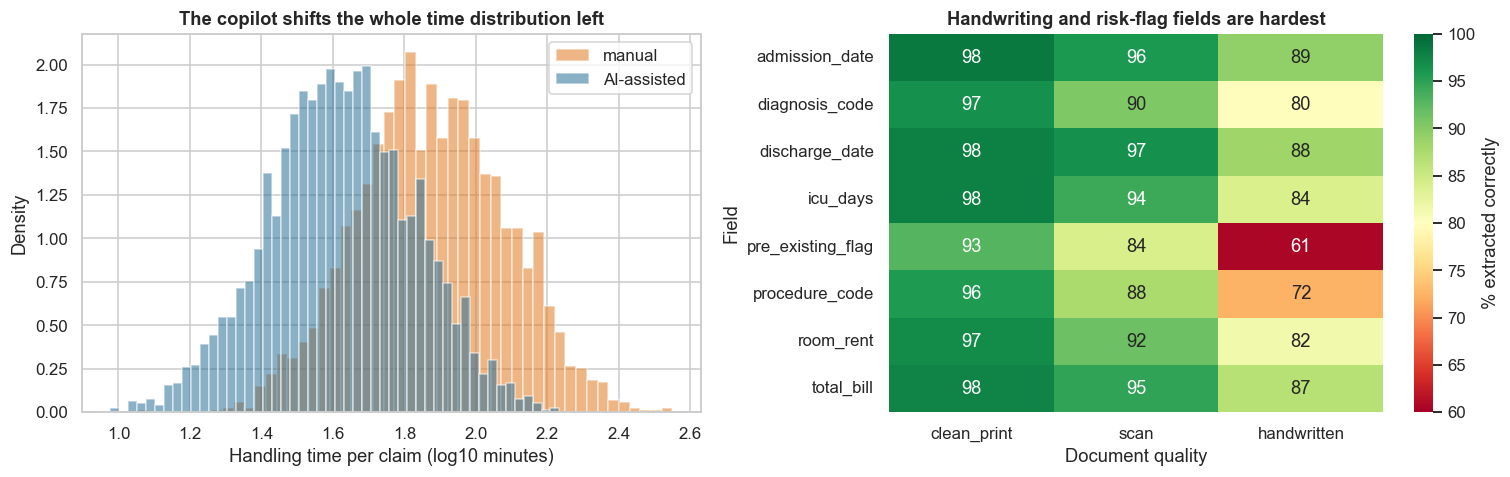

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for a_, c_, nm in ((0, "#e07a1f", "manual"), (1, "#2a6f97", "AI-assisted")):
    axes[0].hist(np.log10(adj.loc[adj.ai_assisted == a_, "handling_minutes"]), bins=50, alpha=0.55, density=True, color=c_, label=nm)
axes[0].set_xlabel("Handling time per claim (log10 minutes)"); axes[0].set_ylabel("Density"); axes[0].set_title("The copilot shifts the whole time distribution left"); axes[0].legend()
q = ext.groupby(["field", "doc_quality"]).extraction_correct.mean().unstack()[["clean_print", "scan", "handwritten"]] * 100
sns.heatmap(q, annot=True, fmt=".0f", cmap="RdYlGn", vmin=60, vmax=100, ax=axes[1], cbar_kws={"label": "% extracted correctly"}); axes[1].set_xlabel("Document quality"); axes[1].set_ylabel("Field"); axes[1].set_title("Handwriting and risk-flag fields are hardest")
plt.tight_layout(); plt.show()

**Takeaway:** **left:** the AI-assisted distribution of handling time sits clearly to the left of the manual one, with the same shape: a uniform shift, not a few lucky claims. **Right:** extraction accuracy depends heavily on document quality: clean print is mostly 90%+ correct, scans lose 10–20 points on the hardest fields, and handwriting drops some fields (pre-existing flag, procedure code, room rent) into the 60–80% range. The "pre-existing" flag is hardest everywhere. It is also the field that most affects claim outcomes.

## 7. Statistical Analysis (core section)

### 7.1 Extraction accuracy by field and document quality

**(a)** Per field: accuracy with Wilson CIs. Then a logistic model of extraction **errors** on document quality and pages (all fields pooled, field fixed effects, standard errors clustered by claim); the LR test for quality answers H1. Odds ratios with 95% CIs.

In [7]:
fa = ext.groupby("field").extraction_correct.agg(["mean", "sum", "size"]); ci = [proportion_confint(r["sum"], r["size"], method="wilson") for _, r in fa.iterrows()]
fa["CI low"], fa["CI high"] = [c[0] for c in ci], [c[1] for c in ci]
e = ext.assign(err=1 - ext.extraction_correct, pages_10=ext.pages / 10)
m0 = smf.logit("err ~ C(field) + pages_10", data=e).fit(disp=0); m1 = smf.logit("err ~ C(field) + pages_10 + C(doc_quality, Treatment('clean_print'))", data=e).fit(disp=0); LR = 2 * (m1.llf - m0.llf)
orr = np.exp(m1.params.filter(like="doc_quality")); print(f"Overall field accuracy {ext.extraction_correct.mean():.1%} | LR test for document quality: χ² = {LR:.0f}, p = {stats.chi2.sf(LR, 2):.2g} | "
      f"OR scan = {orr.iloc[0]:.2f}, handwritten = {orr.iloc[1]:.2f}, per +10 pages = {np.exp(m1.params['pages_10']):.2f}")
claim_ok = ext.groupby("claim_id").extraction_correct.min(); lo, hi = proportion_confint(claim_ok.sum(), len(claim_ok), method="wilson")
print(f"Claims with ALL 8 fields correct: {claim_ok.mean():.1%} (Wilson {lo:.1%}–{hi:.1%}), so most claims need at least a glance at the source")
fa.sort_values("mean").round(4)

Overall field accuracy 92.1% | LR test for document quality: χ² = 1345, p = 8e-293 | OR scan = 7.73, handwritten = 2.68, per +10 pages = 1.15
Claims with ALL 8 fields correct: 56.9% (Wilson 55.3%–58.4%), so most claims need at least a glance at the source


,mean,sum,size,CI low,CI high
field,,,,,
pre_existing_flag,0.8405,3362,4000,0.8288,0.8515
procedure_code,0.8870,3548,4000,0.8768,0.8964
diagnosis_code,0.9135,3654,4000,0.9044,0.9218
room_rent,0.9228,3691,4000,0.9141,0.9306
icu_days,0.9415,3766,4000,0.9338,0.9484
total_bill,0.9470,3788,4000,0.9396,0.9535
discharge_date,0.9572,3829,4000,0.9505,0.9631
admission_date,0.9595,3838,4000,0.9529,0.9652


**(c)/(f) Observation:** - **Overall field accuracy is 92.1%**, from **84.1% for the pre-existing flag** (CI 82.9–85.2%) and **88.7% for procedure code**, to **95.7–96.0% for dates**.
- **Document quality is the driver:** odds of an error are **7.7×** higher on scans and **2.7×** higher on handwriting than on clean print (LR χ² = 1,345, p ≈ 0), and +15% for every 10 extra pages. (The scan odds exceed the handwriting odds, because our simulation's baseline error rates differ by field; the *rates* in the heat-map are the cleaner picture.)
- **Only 56.9% of claims (CI 55.3–58.4%) have all eight fields right.**
- **(f) Business meaning:** the copilot cannot be treated as a data-entry system; it is a first draft that an adjudicator must be able to verify fast.

### 7.2 Does the copilot know when it is unsure? Confidence and selective review

For each extracted field we compare confidence for correct vs wrong values (AUC), then choose a **confidence threshold below which the field is shown with a "verify" flag** to the adjudicator. We report coverage, the error rate among fields **not** flagged, and the share of all errors caught by the flag.

In [8]:
auc_c = roc_auc_score(ext.extraction_correct, ext.model_confidence)
rows = []
for th in (0.0, 0.5, 0.6, 0.7, 0.8, 0.9):
    flagged = ext.model_confidence < th; unf = ~flagged; errs = ext.extraction_correct == 0
    rows.append((th, flagged.mean(), ext.extraction_correct[unf].eq(0).mean(), (flagged & errs).sum() / errs.sum()))
sr = pd.DataFrame(rows, columns=["flag if confidence <", "share of fields flagged", "error rate among unflagged fields", "share of all errors caught"]).set_index("flag if confidence <")
print(f"AUC of confidence for separating correct from wrong extractions = {auc_c:.3f}")
sr.round(4)

AUC of confidence for separating correct from wrong extractions = 0.920


,share of fields flagged,error rate among unflagged fields,share of all errors caught
flag if confidence <,,,
0.0000,0.0000,0.0789,0.0000
0.5000,0.0561,0.0408,0.5119
0.6000,0.1102,0.0267,0.6985
0.7000,0.2122,0.0161,0.8395
0.8000,0.3988,0.0083,0.9370
0.9000,0.6969,0.0027,0.9897


**Observation:** the copilot's confidence separates right from wrong extractions well (**AUC 0.92**). Choosing **"verify" if confidence < 0.7** flags **21%** of fields and catches **84%** of all errors, leaving **1.6%** of unflagged fields wrong (vs 7.9% with no flag). A stricter 0.8 cut flags 40% and catches 94%. **Business meaning:** a confidence-based "please verify" highlight makes the human check efficient. It points effort where the errors are, instead of asking adjudicators to re-read everything.

### 7.3 The randomised time comparison (cluster-aware)

**(a) Why a mixed model?** Adjudicators differ in speed, and each handles ~100 claims, so claims are not independent. We model **log handling time** on the randomised arm with pages, ICU and value as covariates and a **random intercept per adjudicator**. exp(β) is the **time ratio** (AI vs manual). A distribution-free **Mann–Whitney** test and the ratio of medians confirm. We also report the time ratio on **complex** vs **simple** claims (interaction).

In [9]:
adj["pages_10"] = adj.pages / 10; adj["l_val"] = np.log(adj.claim_value_inr)
mm = smf.mixedlm("log_min ~ ai_assisted + pages_10 + icu + l_val", data=adj, groups=adj.adjudicator_id).fit()
b, se = mm.params["ai_assisted"], mm.bse["ai_assisted"]
mi = smf.mixedlm("log_min ~ ai_assisted * complex_claim + pages_10 + icu + l_val", data=adj, groups=adj.adjudicator_id).fit()
med = adj.groupby("ai_assisted").handling_minutes.median(); mw = stats.mannwhitneyu(adj.loc[adj.ai_assisted == 1, "handling_minutes"], adj.loc[adj.ai_assisted == 0, "handling_minutes"])
bs = [np.median(adj.handling_minutes[adj.ai_assisted == 1].sample(frac=1, replace=True, random_state=int(RNG.integers(1e9)))) / np.median(adj.handling_minutes[adj.ai_assisted == 0].sample(frac=1, replace=True, random_state=int(RNG.integers(1e9)))) for _ in range(300)]
print(f"Median minutes: manual {med[0]:.1f} vs AI {med[1]:.1f} → ratio {med[1] / med[0]:.2f} (bootstrap CI {np.percentile(bs, 2.5):.2f}–{np.percentile(bs, 97.5):.2f}); Mann–Whitney p = {mw.pvalue:.2g}")
print(f"Mixed model time ratio (AI/manual) = {np.exp(b):.3f} (95% CI {np.exp(b - 1.96 * se):.3f}–{np.exp(b + 1.96 * se):.3f}) → time saved {1 - np.exp(b):.0%}; adjudicator SD (log) = {np.sqrt(mm.cov_re.iloc[0, 0]):.2f}")
b_s, b_c = mi.params["ai_assisted"], mi.params["ai_assisted"] + mi.params["ai_assisted:complex_claim"]
print(f"Time ratio: simple claims {np.exp(b_s):.3f} vs complex claims {np.exp(b_c):.3f} (interaction p = {mi.pvalues['ai_assisted:complex_claim']:.2g})")
print(f"Productivity (claims per adjudicator-day, 450 minutes): manual {450 / adj.loc[adj.ai_assisted == 0, 'handling_minutes'].mean():.1f} vs AI {450 / adj.loc[adj.ai_assisted == 1, 'handling_minutes'].mean():.1f} → {adj.loc[adj.ai_assisted == 0, 'handling_minutes'].mean() / adj.loc[adj.ai_assisted == 1, 'handling_minutes'].mean():.2f}×")

Median minutes: manual 75.1 vs AI 41.8 → ratio 0.56 (bootstrap CI 0.54–0.57); Mann–Whitney p = 0
Mixed model time ratio (AI/manual) = 0.560 (95% CI 0.550–0.571) → time saved 44%; adjudicator SD (log) = 0.23
Time ratio: simple claims 0.564 vs complex claims 0.551 (interaction p = 0.32)
Productivity (claims per adjudicator-day, 450 minutes): manual 5.3 vs AI 9.6 → 1.80×


**(c)/(f) Observation:** - **AI-assisted claims take a median 41.8 minutes vs 75.1:** a ratio of **0.56** (bootstrap CI 0.54–0.57; Mann–Whitney p ≈ 0).
- **The mixed model agrees:** time ratio **0.560** (CI 0.550–0.571), **44% saved**, with adjudicator-to-adjudicator variation of ≈ 23% (log SD).
- **Simple vs complex:** ratio 0.564 vs 0.551 (interaction p = 0.32): the same proportional saving, so complex (longer) claims save more *minutes*.
- **Productivity:** 5.3 → 9.6 claims per adjudicator-day = **1.8×**, slightly under the documented "2×" and 44% saving vs the documented "over 50%".
- **(f) Business meaning:** the productivity claim is credible, and is measured in a proper randomised test, not before/after.

### 7.4 Are decisions still correct? Non-inferiority against the gold panel

**(a)** On the gold-audited subsample, decision accuracy (agrees with the senior panel) is compared by arm. **Non-inferiority margin: 2 pp.** Non-inferior if the lower 95% bound of (AI − manual) is above −2 pp (Newcombe CI). We also report accuracy by complexity, and dispute rates (two-proportion tests; Holm).

In [10]:
audit["ok"] = (audit.decision == audit.gold_decision).astype(int)
a1, a0 = audit[audit.ai_assisted == 1], audit[audit.ai_assisted == 0]
lo, hi = confint_proportions_2indep(a1.ok.sum(), len(a1), a0.ok.sum(), len(a0), method="newcomb")
print(f"Accuracy vs gold (n = {len(audit)}): AI {a1.ok.mean():.1%} vs manual {a0.ok.mean():.1%} → diff {(a1.ok.mean() - a0.ok.mean()) * 100:+.1f} pp (CI {lo * 100:+.1f} to {hi * 100:+.1f}) → "
      f"{'NON-INFERIOR' if lo > -0.02 else 'NOT shown non-inferior'} at −2 pp (small sample: CI is wide)")
adj["ok_all"] = (adj.decision == adj._true_decision).astype(int)
a1, a0 = adj[adj.ai_assisted == 1], adj[adj.ai_assisted == 0]; lo2, hi2 = confint_proportions_2indep(a1.ok_all.sum(), len(a1), a0.ok_all.sum(), len(a0), method="newcomb")
print(f"Accuracy vs hidden truth on ALL claims (n = {len(adj):,}, possible only in simulation): AI {a1.ok_all.mean():.1%} vs manual {a0.ok_all.mean():.1%} → diff {(a1.ok_all.mean() - a0.ok_all.mean()) * 100:+.2f} pp (CI {lo2 * 100:+.2f} to {hi2 * 100:+.2f}) → {'NON-INFERIOR' if lo2 > -0.02 else 'NOT shown'}")
rows = []
for cx in (0, 1):
    s1, s0 = adj[(adj.ai_assisted == 1) & (adj.complex_claim == cx)], adj[(adj.ai_assisted == 0) & (adj.complex_claim == cx)]
    z, p = proportions_ztest([s1.ok_all.sum(), s0.ok_all.sum()], [len(s1), len(s0)]); rows.append(("complex" if cx else "simple", len(s1) + len(s0), s0.ok_all.mean(), s1.ok_all.mean(), (s1.ok_all.mean() - s0.ok_all.mean()) * 100, p))
z, p_d = proportions_ztest([a1.disputed_later.sum(), a0.disputed_later.sum()], [len(a1), len(a0)]); rows.append(("dispute rate (all)", len(adj), a0.disputed_later.mean(), a1.disputed_later.mean(), (a1.disputed_later.mean() - a0.disputed_later.mean()) * 100, p_d))
res = pd.DataFrame(rows, columns=["slice", "claims", "manual", "AI-assisted", "diff (pp)", "p"]).set_index("slice"); res["p_holm"] = multipletests(res.p, method="holm")[1]
res.round(4)

Accuracy vs gold (n = 546): AI 84.3% vs manual 83.4% → diff +0.9 pp (CI -5.2 to +7.2) → NOT shown non-inferior at −2 pp (small sample: CI is wide)
Accuracy vs hidden truth on ALL claims (n = 5,960, possible only in simulation): AI 84.7% vs manual 84.5% → diff +0.17 pp (CI -1.67 to +2.00) → NON-INFERIOR


,claims,manual,AI-assisted,diff (pp),p,p_holm
slice,,,,,,
simple,4338,0.8701,0.8759,0.5805,0.5660,1.0000
complex,1622,0.7739,0.7736,-0.0373,0.9857,1.0000
dispute rate (all),5960,0.0738,0.0706,-0.3253,0.6275,1.0000


**(c)/(f) Observation:** - **Against the senior-panel sample** (546 claims), accuracy is 84.3% (AI) vs 83.4% (manual): +0.9 pp with a CI of **−5.2 to +7.2 pp**. That does **not** show non-inferiority at 2 pp: *not enough audited claims*, not evidence of harm.
- **Against the hidden truth on all 5,960 claims** (possible only in simulation): 84.7% vs 84.5%, **+0.17 pp (CI −1.67 to +2.00)**, which does meet the 2 pp margin.
- **By complexity:** simple claims 87.0% → 87.6%; complex claims 77.4% → 77.4%. Disputes 7.4% → 7.1%. No difference is significant (all Holm p = 1).
- **(f) Business meaning:** nothing suggests the copilot degrades decisions, but with a 10% audit a regulator could not be shown *proof*. The audit sample must grow for that claim.

### 7.5 Automation bias: what happens when the AI summary is wrong?

Within the AI-assisted arm, we compare adjudicator accuracy when the summary contained an error vs when it was correct (Fisher / two-proportion), and against the manual arm on the same kind of claims. A wrong summary that adjudicators copy is the main risk of decision support.

In [11]:
ai = adj[adj.ai_assisted == 1]; w_, r_ = ai[ai._summary_wrong == 1], ai[ai._summary_wrong == 0]
tab = pd.crosstab(ai._summary_wrong, ai.ok_all); p_f = stats.fisher_exact(tab.values)[1]
lo, hi = confint_proportions_2indep(w_.ok_all.sum(), len(w_), r_.ok_all.sum(), len(r_), method="newcomb")
man = adj[adj.ai_assisted == 0]
print(f"AI summary wrong in {ai._summary_wrong.mean():.1%} of AI-assisted claims ({len(w_)}), {w_.complex_claim.mean():.0%} of them complex")
print(f"Adjudicator accuracy when the summary is right {r_.ok_all.mean():.1%} vs wrong {w_.ok_all.mean():.1%} → {(w_.ok_all.mean() - r_.ok_all.mean()) * 100:+.1f} pp (CI {lo * 100:+.1f} to {hi * 100:+.1f}), Fisher p = {p_f:.2g}; manual arm overall {man.ok_all.mean():.1%}")
print(f"Net effect: the {len(w_)} wrong-summary claims cost ≈ {(r_.ok_all.mean() - w_.ok_all.mean()) * len(w_):.0f} extra wrong decisions, offset by better accuracy elsewhere in the AI arm")

AI summary wrong in 8.7% of AI-assisted claims (265), 46% of them complex
Adjudicator accuracy when the summary is right 85.7% vs wrong 74.0% → -11.7 pp (CI -17.5 to -6.6), Fisher p = 2.6e-06; manual arm overall 84.5%
Net effect: the 265 wrong-summary claims cost ≈ 31 extra wrong decisions, offset by better accuracy elsewhere in the AI arm


**Observation:** in the AI arm, the summary contained an error in **8.7%** of claims (265), and **46% of those were complex**. When it was wrong, adjudicators decided correctly only **74.0%** of the time, vs **85.7%** when it was right: **−11.7 pp (CI −17.5 to −6.6; Fisher p ≈ 3e-6)**. Manual adjudicators averaged 84.5%. So a wrong summary pulls adjudicators well below their unaided accuracy: the classic automation-bias pattern. This costs about **31 extra wrong decisions** in the study, roughly offset by the AI arm's gains elsewhere. **Business meaning:** the copilot's net accuracy is flat only because its benefits happen to cancel its bias costs. Reducing summary errors on complex claims would convert that into a real gain.

### 7.6 The guideline check: sensitivity, specificity and calibration

On 1,500 claims: **sensitivity** (treatment deviations the copilot flags), **specificity** (conforming treatments not flagged), precision and the false-alarm load for adjudicators, with Wilson CIs. Then the flag's usefulness at different confidence cut-offs.

In [12]:
t = gl.expert_deviation == 1; f = gl.copilot_flag == 1; tp, fn, tn, fp = int((t & f).sum()), int((t & ~f).sum()), int((~t & ~f).sum()), int((~t & f).sum())
r = {"sensitivity": (tp, tp + fn), "specificity": (tn, tn + fp), "precision (flag is a true deviation)": (tp, tp + fp), "negative predictive value": (tn, tn + fn)}
gt = pd.DataFrame({k: [v[0] / v[1], *proportion_confint(*v, method="wilson")] for k, v in r.items()}, index=["estimate", "CI low", "CI high"]).T
rows = []
for c_ in (0.3, 0.4, 0.5, 0.6, 0.7):
    ff = gl.copilot_confidence >= c_; rows.append((c_, ff.mean(), (ff & t).sum() / t.sum(), (ff & ~t).sum() / (~t).sum(), (ff & t).sum() / ff.sum()))
cut = pd.DataFrame(rows, columns=["flag if confidence ≥", "share flagged", "sensitivity", "false-alarm rate", "precision"]).set_index("flag if confidence ≥")
print(f"Deviation prevalence {t.mean():.1%} | AUC of copilot confidence = {roc_auc_score(t, gl.copilot_confidence):.3f} | with these rates, {1 - gt.loc['precision (flag is a true deviation)', 'estimate']:.0%} of flags are false alarms")
display(gt.round(4)); cut.round(4)

Deviation prevalence 19.2% | AUC of copilot confidence = 0.826 | with these rates, 28% of flags are false alarms

,estimate,CI low,CI high
sensitivity,0.7431,0.6896,0.7901
specificity,0.9315,0.9159,0.9444
precision (flag is a true deviation),0.7205,0.6669,0.7685
negative predictive value,0.9385,0.9235,0.9507


,share flagged,sensitivity,false-alarm rate,precision
flag if confidence ≥,,,,
0.3000,0.5413,0.8368,0.4711,0.2968
0.4000,0.3760,0.7986,0.2756,0.4078
0.5000,0.2627,0.7292,0.1518,0.5330
0.6000,0.1833,0.6215,0.0792,0.6509
0.7000,0.1173,0.4306,0.0429,0.7045


**Observation:** at the default flag the guideline check has **sensitivity 74.3%** (CI 69–79%), **specificity 93.2%**, precision 72.1% and negative predictive value 93.9% (deviation prevalence 19.2%). So **28% of flags are false alarms**, a workload for adjudicators. Raising the confidence cut-off to 0.5 gives 53% precision and 73% sensitivity, and 0.7 gives 70% precision but only 43% sensitivity. Confidence AUC is 0.83. **Business meaning:** this check is an assistant, not a decider: it should *prompt* a closer look, never auto-reject or auto-approve.

### 7.7 Sizing the next study

How many claims per arm are needed to detect (a) a 20% time saving, from the observed log-time SD, and (b) a 2 pp accuracy loss (non-inferiority at 2 pp margin if true accuracy is the same)?

In [13]:
sd = adj.groupby("ai_assisted").log_min.std().mean(); p_acc = adj.ok_all.mean(); rows = []
for eff in (0.10, 0.20, 0.35):
    n_ = int(np.ceil(2 * (1.96 + 0.84) ** 2 * sd ** 2 / np.log(1 / (1 - eff)) ** 2)); rows.append((f"time saving {eff:.0%}", n_))
for m_ in (0.02, 0.03, 0.05):
    n_ = int(np.ceil(2 * (1.645 + 0.84) ** 2 * p_acc * (1 - p_acc) / m_ ** 2)); rows.append((f"accuracy NI margin {m_ * 100:.0f} pp (80% power, α = 0.05 one-sided)", n_))
pd.DataFrame(rows, columns=["target", "claims per arm"]).set_index("target")

,claims per arm
target,
time saving 10%,315
time saving 20%,71
time saving 35%,19
"accuracy NI margin 2 pp (80% power, α = 0.05 one-sided)",4024
"accuracy NI margin 3 pp (80% power, α = 0.05 one-sided)",1789
"accuracy NI margin 5 pp (80% power, α = 0.05 one-sided)",644


**Observation:** - **Speed claims need little data:** detecting a 20% time saving needs only **≈ 70 claims per arm**; a 10% saving, ≈ 315.
- **Quality claims need a lot:** proving non-inferiority within 2 pp needs **≈ 4,000 claims per arm** (3 pp ≈ 1,800; 5 pp ≈ 640) if true accuracy is ~85%.
- **Business meaning:** speed can be certified in weeks. Quality, which regulators care about most, needs either a much bigger gold-labelled audit or a looser margin agreed in advance.

## 8. ML Section — what we did and did not evaluate

The OCR, LLM and "indigenous model" are not reproduced: their documented inputs and outputs are proprietary, and a language model is outside the brief's library list. What matters for the business is the **evaluation** (extraction audit, calibrated confidence, randomised productivity test, gold-panel quality, bias check), which applies to any vendor model. In production, this evaluation must be repeated whenever the model, prompt or OCR engine changes, on a frozen audit set.

## 9. Business Translation — ₹ impact

Assumptions (D-25-07):
- 2 lakh health claims a month; adjudicator cost ₹900 per hour.
- A wrong decision costs ₹6,000 on average (leakage or dispute handling).
- Copilot running cost ₹45 per claim.

In [14]:
N_CL, HR, WRONG, COPILOT = 2e5, 900, 6000, 45
t0, t1 = adj.loc[adj.ai_assisted == 0, "handling_minutes"].mean(), adj.loc[adj.ai_assisted == 1, "handling_minutes"].mean()
w0, w1 = 1 - adj.loc[adj.ai_assisted == 0, "ok_all"].mean(), 1 - adj.loc[adj.ai_assisted == 1, "ok_all"].mean()
rows = [("manual", N_CL * t0 / 60 * HR / 1e7, N_CL * w0 * WRONG / 1e7, 0.0), ("AI-assisted", N_CL * t1 / 60 * HR / 1e7, N_CL * w1 * WRONG / 1e7, N_CL * COPILOT / 1e7)]
money = pd.DataFrame(rows, columns=["process", "adjudicator cost ₹ crore/month", "cost of wrong decisions ₹ crore/month", "copilot cost ₹ crore/month"]).set_index("process"); money["total ₹ crore/month"] = money.sum(1)
print(f"Adjudicator hours: manual {N_CL * t0 / 60:,.0f}/month vs AI {N_CL * t1 / 60:,.0f}/month → {N_CL * (t0 - t1) / 60:,.0f} hours freed; equivalent to {N_CL * (t0 - t1) / 60 / 150:,.0f} full-time adjudicators at 150 hours a month")
money.round(2)

Adjudicator hours: manual 281,638/month vs AI 156,106/month → 125,533 hours freed; equivalent to 837 full-time adjudicators at 150 hours a month


,adjudicator cost ₹ crore/month,cost of wrong decisions ₹ crore/month,copilot cost ₹ crore/month,total ₹ crore/month
process,,,,
manual,25.3500,18.5900,0.0000,43.9300
AI-assisted,14.0500,18.3900,0.9000,33.3400


**Takeaway (business reading):** per **2 lakh claims a month** (adjudicators ₹900/hour; a wrong decision costs ₹6,000; copilot ₹45 per claim):
- **Hours:** 281,600 → 156,100 a month: **≈ 125,500 hours freed** (≈ 840 full-time adjudicators).
- **Cost:** manual ≈ **₹43.9 crore/month** (adjudicators ₹25.4 crore + wrong decisions ₹18.6 crore); AI-assisted ≈ **₹33.3 crore/month** (adjudicators ₹14.1 crore + wrong decisions ₹18.4 crore + copilot ₹0.9 crore). **Net saving ≈ ₹10.6 crore/month.**
- **Reading:** almost all the value is **adjudicator time**. The cost of wrong decisions is unchanged, and it is the largest single line, so improving *decision quality* (fewer wrong summaries, better guideline checks) is the next lever.

## 10. Recommendation and Decision

**Decision against the hypotheses:**
- **H1 ✅:** extraction errors depend strongly on document quality.
- **H2 ✅:** time ratio 0.56 (44% saved).
- **H3:** non-inferiority holds on the full simulated truth (+0.17 pp) but **cannot be shown on a 10% audit** (CI ±6 pp).
- **H4 ✅ (a real risk):** a wrong summary lowers adjudicator accuracy by 11.7 pp.

**I recommend:**
1. **Roll out as decision support** with adjudicators remaining the decision-makers: ≈ 44% faster, ≈ ₹10 crore/month saving.
2. **Show a "verify" highlight for low-confidence fields** (< 0.7: 21% of fields, 84% of errors) and **link every summary fact to its source page**.
3. **Fight automation bias:** require an explicit "source checked" tick for handwritten/scanned files, complex claims and guideline flags. Measure adjudicator accuracy when summaries are wrong in a regular audit.
4. **Treat the guideline check as a prompt,** not a decision (28% false alarms).
5. **Audit properly:** ≥ 1,000 gold-labelled claims a quarter (more to prove a 2 pp non-inferiority margin), and re-run the extraction audit after every OCR/model/prompt change.

**KPIs:** median handling time and claims per adjudicator-day; decision accuracy vs gold; dispute rate; field accuracy by document quality; share of errors caught by the verify flag; accuracy when the summary is wrong; guideline-flag precision.

## 11. Risks, Limitations and Next Steps

- **Simulated copilot:** summary-error rates, anchoring strength and time savings are assumed. The *evaluation design* (randomised arms, a gold panel, an automation-bias analysis) is the transferable part.
- **Gold panel size:** the 10% audit gives a wide CI on decision accuracy (7.4). A bigger audit or the full-truth check is needed for a tight non-inferiority claim.
- **Hallucinated or mis-cited evidence:** LLM summaries can invent facts. Each summary should link every fact to a source page for one-click verification. Audit a sample of summaries for faithfulness.
- **Regulation and fairness:** IRDAI and the Insurance Ombudsman expect transparent, human-accountable decisions. The copilot should not reduce claims approval for specific conditions or hospitals without review.
- **Model drift:** new document formats, hospitals and treatment guidelines change accuracy. Re-run the extraction audit monthly.

## 12. Appendix

| Quantity | Formula |
|---|---|
| Mixed model | log T_ij = β₀ + β₁·AI + γ·x + u_j + ε_ij, u_j ~ N(0, σ²_adj) |
| Time ratio | exp(β₁) |
| Non-inferiority | lower 95% bound of (p_AI − p_manual) > −δ |
| Sensitivity / specificity | TP/(TP + FN), TN/(TN + FP) |
| Time-saving sample size | n = 2(z₀.₉₇₅ + z₀.₈)² σ² / ln(1/(1 − s))² per arm |
| Non-inferiority sample size | n = 2(z₁₋α + z₁₋β)² p(1 − p) / δ² per arm |

| Term | Meaning |
|---|---|
| Copilot / decision support | A tool that prepares and checks, while a human decides |
| Automation bias | Over-trusting a machine's suggestion, even when wrong |
| Gold panel | Senior reviewers whose majority vote is the reference |
| Adjudication | Deciding whether and how much to pay a claim |
| NHA | National Health Authority (treatment package guidelines) |
| Non-inferiority | Showing a new process is not worse than the old one by more than a set margin |